# Part 1 - Acquisition and storage

BFT65B final report, walkthrough notebook. Every number below is read from `reports/` or recomputed live by the same scripts the README lists. Seed: `config.SEED = 42`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
import polars as pl
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import config as C

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
R = ROOT / "reports"
print("project root:", ROOT, "| python", sys.version.split()[0], "| polars", pl.__version__, "| seed", C.SEED)


def run(script, *args, tail=25):
    """Run one pipeline script exactly as the README does, and show the end of its output."""
    t = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"})
    lines = (t.stdout + t.stderr).strip().splitlines()
    print("\n".join(lines[-tail:]))
    print(f"\n>>> {script} {' '.join(args)} exited with {t.returncode}")
    assert t.returncode == 0, "step failed"


def csv(name, n=None):
    df = pd.read_csv(R / name)
    display(df if n is None else df.head(n))


def fig(name, width=820):
    display(Image(filename=str(R / name), width=width))

project root: D:\Final BigData | python 3.15.2 | polars 2.1.0 | seed 42


**Goal.** Download the full FDIC scope reproducibly, prove it is complete, and store it in a layout that
beats raw CSV on measured size and query time.

| Step | Script | Run here? |
|---|---|---|
| Download (resumable, 15-60 min) | `fdic_download_full.py` | no, already done |
| Completeness, control totals, SHA-256, schema drift | `src/p1_verify.py` | **yes, live** |
| Typed bronze layer, reconciled against raw | `src/p1_build_bronze.py` | **yes, live** |
| Storage layouts benchmark (about 4 min, 3 GB scratch) | `src/p1_storage_benchmark.py` | no, results shown |

The second, independent download (`data_raw/fdic`, starter field list) is compared when it is present.

In [2]:
run('src/p1_verify.py', *(['--compare', 'data_raw/fdic'] if (ROOT / 'data_raw' / 'fdic').exists() else []))

  "max_abs_bank_diff": 303,
  "max_abs_asset_diff_pct": 2.0506
 },
 "independent_download": {
  "other_download": "data_raw\\fdic",
  "quarters_compared": 170,
  "shared_columns": 32,
  "cells_compared": 53843712,
  "cells_different": 0,
  "columns_with_differences": {}
 },
 "ok": true
}
shape: (5, 8)
┌──────────────┬────────────┬──────┬───────────┬───────────────┬─────────────────────────┬────────────┬────────────┐
│ period       ┆ RESTYPE    ┆ rows ┆ null_cert ┆ distinct_cert ┆ rows_with_panel_history ┆ first      ┆ last       │
│ ---          ┆ ---        ┆ ---  ┆ ---       ┆ ---           ┆ ---                     ┆ ---        ┆ ---        │
│ str          ┆ str        ┆ u32  ┆ u32       ┆ u32           ┆ u32                     ┆ date       ┆ date       │
╞══════════════╪════════════╪══════╪═══════════╪═══════════════╪═════════════════════════╪════════════╪════════════╡
│ after 2026Q2 ┆ FAILURE    ┆ 2    ┆ 0         ┆ 2             ┆ 2                       ┆ 2026-07-10 ┆ 2026-07-

In [3]:
run('src/p1_build_bronze.py')

financials: 1,682,616 rows, 43 partitions, 206.31 MB, 2.6 s
failures: 4,117 rows, 11 columns
institutions: 27,835 rows, 11 columns

>>> src/p1_build_bronze.py  exited with 0


### Completeness against the API control totals

In [4]:
print(json.dumps(json.loads((R / 'p1_completeness.json').read_text()), indent=1)[:1500])

{
 "raw_folder": "D:\\Final BigData\\data_raw\\fdic_full",
 "financials": {
  "quarters_expected": 170,
  "quarters_on_disk": 170,
  "quarters_missing": [],
  "quarters_rows_differ_from_api": [],
  "quarters_wrong_repdte_inside": [],
  "panel_rows": 1682616,
  "distinct_banks": 24064,
  "null_keys": 0,
  "duplicate_cert_repdte": 0,
  "api_index": "risview_20260819185831",
  "api_index_created": "2026-08-19T18:58:33Z"
 },
 "failures": {
  "rows": 4117,
  "exact_duplicate_rows": 0,
  "null_cert": 488,
  "api_total": 4117,
  "api_index": "failures_1787667198788",
  "api_index_created": "2026-08-25T14:13:18Z"
 },
 "institutions": {
  "rows": 27835,
  "exact_duplicate_rows": 0,
  "null_cert": 0,
  "api_total": 27835,
  "api_index": "institutions_20261106100008",
  "api_index_created": "2026-11-06T13:05:30Z"
 },
 "field_list_matches_config": true,
 "download_log": {
  "source": "https://api.fdic.gov/banks",
  "started_utc": "2026-11-07T11:13:52+00:00",
  "finished_utc": "2026-11-07T11:30:24+

In [5]:
csv('p1_control_totals.csv', 10)

,YEAR,panel_banks,panel_asset,not_in_institutions_banks,not_in_institutions_asset,fdic_banks,fdic_asset,banks_diff,asset_diff_pct
0,1984,17949,3659538669,35,4250862,17914,3653117320,0,0.0594
1,1985,18082,4000970821,34,5539401,18043,3993326324,5,0.0527
2,1986,17930,4336109258,33,6028022,17887,4327565137,10,0.0581
3,1987,17384,4510063396,36,5228369,17345,4502059540,3,0.0616
4,1988,16632,4770365485,41,6687870,16575,4758966067,16,0.0990
5,1989,16152,4840174315,46,6639022,15803,4736408670,303,2.0506
6,1990,15426,4748962352,52,7749528,15163,4656548263,211,1.8182
7,1991,14664,4609566773,52,7006282,14489,4550192185,123,1.1509
8,1992,14028,4596531395,55,8262445,13858,4541325436,115,1.0337
9,1993,13388,4750834083,50,8146635,13224,4711354008,114,0.6651


### The bronze layer, read lazily with Polars (only the needed columns and partitions are touched)

In [6]:
lf = pl.scan_parquet(C.DATA_BRONZE / "financials" / "**/*.parquet", hive_partitioning=True)
print(lf.select(pl.len()).collect())
lf.group_by("YEAR").agg(pl.len().alias("rows"), pl.col("CERT").n_unique().alias("banks")).sort("YEAR").collect().head(8)

shape: (1, 1)
┌─────────┐
│ len     │
│ ---     │
│ u32     │
╞═════════╡
│ 1682616 │
└─────────┘


YEAR,rows,banks
i64,u32,u32
1984,71760,18330
1985,71961,18502
1986,72182,18409
1987,70399,18052
1988,67715,17469
1989,65397,16804
1990,62769,16309
1991,59949,15467


### Storage benchmark: CSV against the chosen ZSTD-3 Parquet layout

In [7]:
display(Markdown((R / 'p1_storage_benchmark.md').read_text(encoding='utf-8')))

| layout           |   size_mb |   files |   write_s |   W1_s |   W2_s |   W3_s |   W4_s |   W5_s |   W6_s |   W3_needed_pct |   W4_needed_pct |   W5_needed_pct |   W6_needed_pct |   size_vs_csv |
|:-----------------|----------:|--------:|----------:|-------:|-------:|-------:|-------:|-------:|-------:|----------------:|----------------:|----------------:|----------------:|--------------:|
| csv              |     490.2 |       1 |     0.478 | 0.4209 | 2.2057 | 0.212  | 0.2236 | 0.467  | 0.2563 |           100   |           100   |           100   |           100   |         1     |
| csv_gz           |     220.1 |       1 |     8.901 | 1.5952 | 3.5437 | 1.3378 | 1.305  | 1.6483 | 1.4185 |           100   |           100   |           100   |           100   |         0.449 |
| pq_none_1file    |     373.5 |       1 |     0.377 | 0.357  | 0.5809 | 0.0168 | 0.0196 | 0.0097 | 0.0246 |             3.9 |             3.8 |             1   |             7.7 |         0.762 |
| pq_snappy_1file  |     259   |       1 |     0.389 | 0.1125 | 0.3649 | 0.0342 | 0.0189 | 0.0153 | 0.0214 |             3.1 |             5.1 |             1   |             8.1 |         0.528 |
| pq_zstd_1file    |     197   |       1 |     0.475 | 0.2308 | 0.4001 | 0.035  | 0.074  | 0.013  | 0.0219 |             2.3 |             6.3 |             1   |             8.5 |         0.402 |
| pq_year          |     206.3 |      43 |     1.056 | 0.1153 | 0.4075 | 0.0216 | 0.0128 | 0.0524 | 0.0126 |             3.7 |             0.1 |            42.7 |             0.2 |         0.421 |
| pq_year_rg4k     |     207.6 |      43 |     1.712 | 0.1473 | 0.3874 | 0.0414 | 0.0139 | 0.0348 | 0.0137 |             3.7 |             0.1 |            10.9 |             0.2 |         0.424 |
| pq_year_rg64k    |     204.6 |      43 |     1.323 | 0.1211 | 0.2675 | 0.0339 | 0.0124 | 0.0788 | 0.0132 |             3.8 |             0.1 |            98.7 |             0.2 |         0.417 |
| pq_year_sortdate |     213.9 |      43 |     1.309 | 0.1231 | 0.3349 | 0.022  | 0.0121 | 0.0873 | 0.011  |             4.4 |             0.1 |            91.4 |             0.1 |         0.436 |
| pq_year_float    |     206.6 |      43 |     1.248 | 0.145  | 0.3245 | 0.0231 | 0.0138 | 0.057  | 0.0122 |             3.9 |             0.1 |            42.9 |             0.2 |         0.421 |
| pq_quarter       |     215.3 |     170 |     1.921 | 0.141  | 0.3396 | 0.0321 | 0.0213 | 0.1543 | 0.0154 |             4.3 |             0.1 |            98.7 |             0.1 |         0.439 |
| delta_year       |     249.2 |      44 |     4.39  | 0.1459 | 0.5528 | 0.0365 | 0.0313 | 0.0546 | 0.0209 |             4.1 |             0.1 |            42.9 |             0.2 |         0.508 |

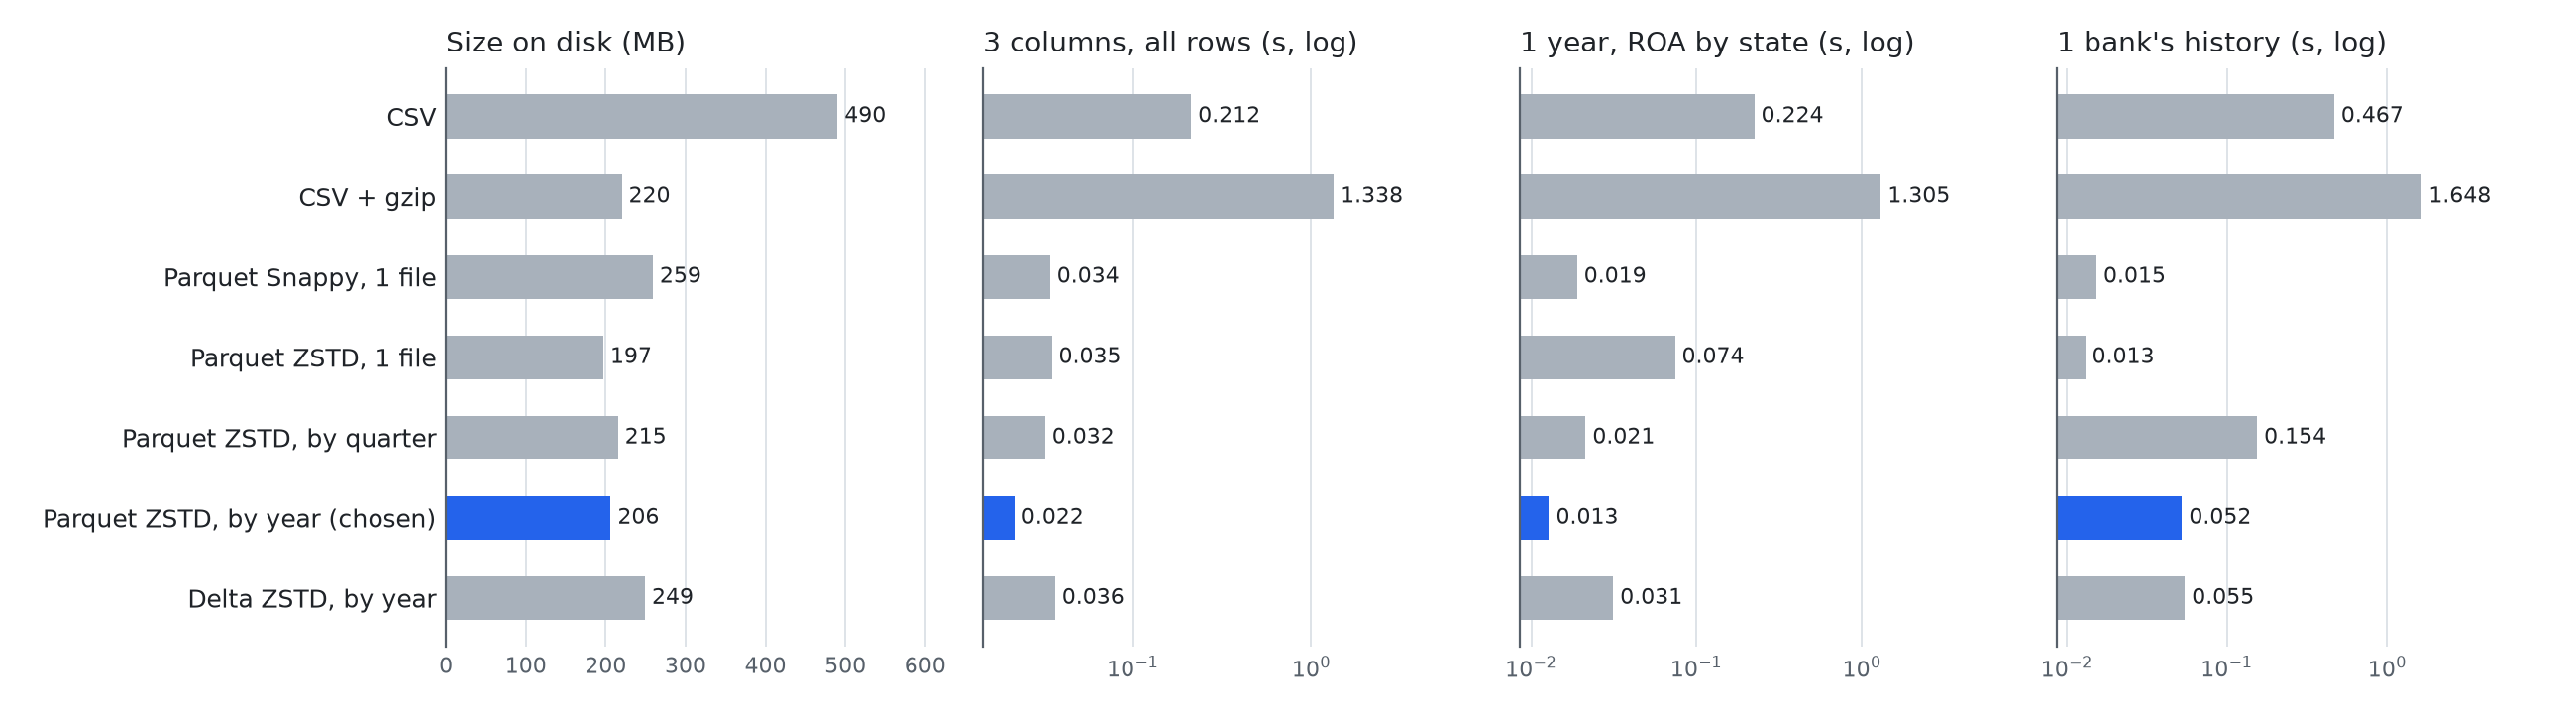

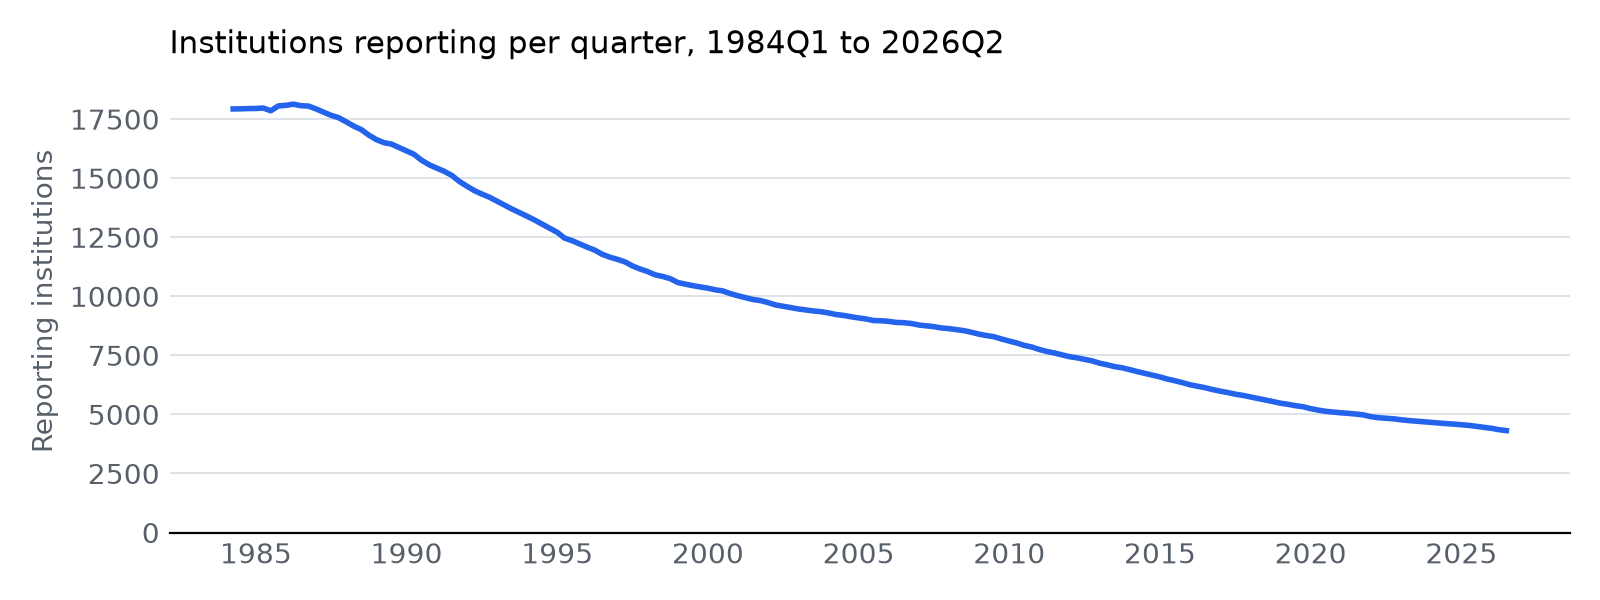

In [8]:
fig('fig_p1_storage.png'); fig('fig_p1_coverage.png')